# EDA — Smart Wardrobe

Notebook ini melakukan **Exploratory Data Analysis** untuk dua dataset yang dipakai pada pipeline ML:

1. **Fashion Product Images (Small)** — katalog untuk melatih *auto-tagger* CNN (Model 1).
2. **Polyvore (Re-PolyVore)** — outfit untuk melatih *compatibility scorer* Bi-LSTM (Model 2).

Struktur folder yang diasumsikan (lihat `ml/README.md`):

```
ml/data/fashionProduct/styles.csv + images/{id}.jpg
ml/data/polyvore/{train,valid,test}_no_dup.json, category_id.txt,
                 fashion_compatibility_prediction.txt,
                 Re-PolyVore/{category}/{set_id}_{index}.jpg
```

> Notebook ini tidak mengubah data apa pun; hanya membaca dan membuat ringkasan.

## 0. Setup

In [1]:
import os, sys, json
from pathlib import Path
from collections import Counter

# Pastikan working directory = folder ml/ (tempat config_utils.py berada).
HERE = Path.cwd()
if not (HERE / "config_utils.py").exists():
    if (HERE / "ml" / "config_utils.py").exists():
        os.chdir(HERE / "ml")
    else:
        raise RuntimeError("Buka/run notebook ini dari folder ml/.")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (12, 4)

import config_utils as cu

ARTIFACT_DIR = cu.ensure_dir(cu.artifact_dir() / "eda")
print("data     :", cu.to_posix(cu.data_dir()))
print("artifacts:", cu.to_posix(ARTIFACT_DIR))

data     : C:/Kuliah/Semester 5/neurfit/ml/data
artifacts: C:/Kuliah/Semester 5/neurfit/ml/artifacts/eda


## 1. Dataset Fashion Product Images

Label mentah akan dipetakan ke taksonomi di `ml/configs/labels.yaml` (sumber tunggal):

- `article_type`: 23 kelas didukung + `other`
- `base_colour`: 14 keluarga warna
- `usage`: 5 kelas (Ethnic/Home/kosong hanya di-*mask*, barisnya tetap dipakai)

In [2]:
labels = cu.load_labels()
SEED = int(labels.get("seed", 42))
OTHER_MAX = int(labels.get("other_class_max_samples", 4000))
EXCLUDE_GENDER = ("Boys", "Girls")

article_ds_to_key = {e["dataset"]: e["key"] for e in labels["article_type"] if e.get("dataset")}
article_to_slot = {e["key"]: e.get("slot") for e in labels["article_type"]}
colour_ds_to_key = {ds: e["key"] for e in labels["base_colour"] for ds in e["dataset"]}
usage_ds_to_key = {ds: e["key"] for e in labels["usage"] for ds in e["dataset"]}

raw_dir = cu.fashion_raw_dir()
styles_csv = raw_dir / "styles.csv"
images_dir = raw_dir / "images"
print("styles.csv:", cu.to_posix(styles_csv))
print("images dir:", cu.to_posix(images_dir))

# on_bad_lines='skip' WAJIB: sebagian baris CSV rusak (PRD A-01).
styles = pd.read_csv(styles_csv, on_bad_lines="skip")
print("rows:", len(styles), "| cols:", len(styles.columns))
display(styles.head())
display(styles[["id", "gender", "articleType", "baseColour", "usage"]].isna().sum().to_frame("missing"))

styles.csv: C:/Kuliah/Semester 5/neurfit/ml/data/fashionProduct/styles.csv
images dir: C:/Kuliah/Semester 5/neurfit/ml/data/fashionProduct/images


rows:

 44424 | cols: 10


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


,missing
id,0
gender,0
articleType,0
baseColour,15
usage,317


gender:
 gender
Men       22147
Women     18631
Unisex     2161
Boys        830
Girls       655

usage:
 usage
Casual          34406
Sports           4025
Ethnic           3208
Formal           2345
<NA>              317
Smart Casual       67
Party              29
Travel             26
Home                1

articleType unik: 143 | baseColour unik: 46
duplicate ids: 0


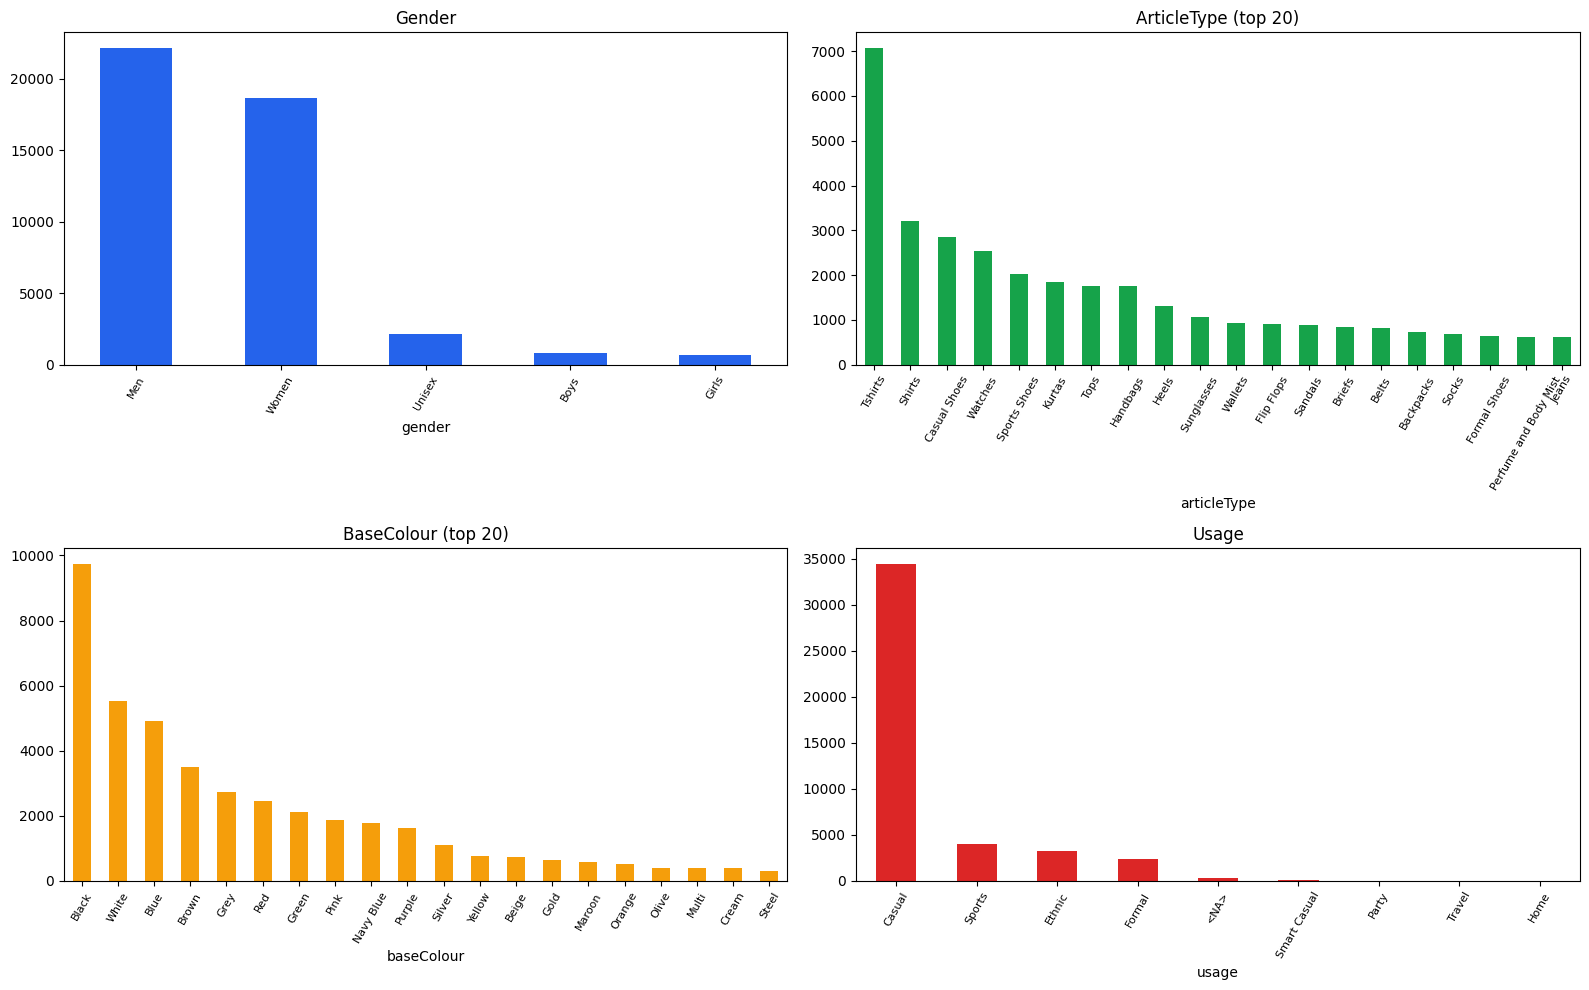

In [3]:
print("gender:\n", styles["gender"].value_counts().to_string())
print("\nusage:\n", styles["usage"].fillna("<NA>").value_counts().to_string())
print("\narticleType unik:", styles["articleType"].nunique(),
      "| baseColour unik:", styles["baseColour"].nunique())
print("duplicate ids:", int(styles["id"].duplicated().sum()))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
styles["gender"].value_counts().plot.bar(ax=axes[0, 0], color="#2563EB", title="Gender")
styles["articleType"].value_counts().head(20).plot.bar(ax=axes[0, 1], color="#16A34A", title="ArticleType (top 20)")
styles["baseColour"].value_counts().head(20).plot.bar(ax=axes[1, 0], color="#F59E0B", title="BaseColour (top 20)")
styles["usage"].fillna("<NA>").value_counts().plot.bar(ax=axes[1, 1], color="#DC2626", title="Usage")
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=60, labelsize=8)
plt.tight_layout()
plt.show()

### 1.1 Ketersediaan & karakteristik gambar

gambar ada   : 44419 / 44424
gambar hilang: 5


sample: 3000 | corrupt: 0 | modes: {'RGB': 2969, 'L': 31}
width  min/median/max: 53/60/60
height min/median/max: 77/80/80
aspect p05/median/p95: 0.75/0.75/0.75


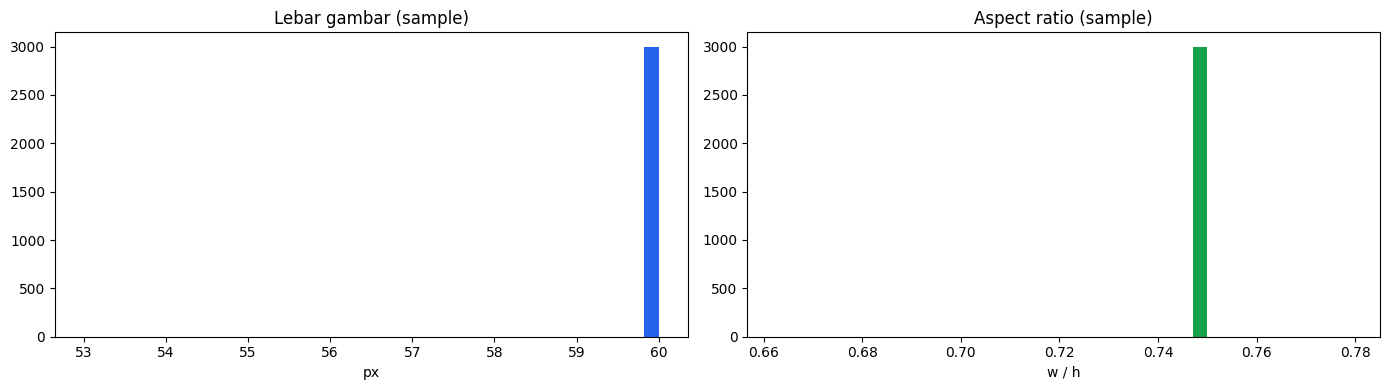

In [4]:
from PIL import Image

paths = [images_dir / f"{i}.jpg" for i in styles["id"]]
exists = np.fromiter((p.exists() for p in paths), dtype=bool, count=len(paths))
print(f"gambar ada   : {int(exists.sum())} / {len(styles)}")
print(f"gambar hilang: {int((~exists).sum())}")

SAMPLE_N = 3000
sample = styles[exists].sample(n=min(SAMPLE_N, int(exists.sum())), random_state=SEED)
widths, heights, modes, corrupt = [], [], Counter(), []
for img_id in sample["id"]:
    p = images_dir / f"{img_id}.jpg"
    try:
        with Image.open(p) as im:
            widths.append(im.size[0])
            heights.append(im.size[1])
            modes[im.mode] += 1
    except Exception:
        corrupt.append(str(p))

w = np.array(widths)
h = np.array(heights)
aspect = w / np.maximum(h, 1)
print("sample:", len(widths), "| corrupt:", len(corrupt), "| modes:", dict(modes))
print(f"width  min/median/max: {w.min()}/{int(np.median(w))}/{w.max()}")
print(f"height min/median/max: {h.min()}/{int(np.median(h))}/{h.max()}")
print(f"aspect p05/median/p95: {np.percentile(aspect,5):.2f}/{np.median(aspect):.2f}/{np.percentile(aspect,95):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(w, bins=40, color="#2563EB")
axes[0].set_title("Lebar gambar (sample)")
axes[0].set_xlabel("px")
axes[1].hist(aspect, bins=40, color="#16A34A")
axes[1].set_title("Aspect ratio (sample)")
axes[1].set_xlabel("w / h")
plt.tight_layout()
plt.show()

### 1.2 Coverage pemetaan label

In [5]:
raw = styles[["id", "gender", "articleType", "baseColour", "usage"]].copy()
raw = raw[raw["articleType"].notna() & raw["baseColour"].notna()]

mapped_art = raw["articleType"].map(article_ds_to_key)
mapped_col = raw["baseColour"].map(colour_ds_to_key)
mapped_usg = raw["usage"].map(usage_ds_to_key)

print("articleType mapped :", int(mapped_art.notna().sum()), "| other:", int(mapped_art.isna().sum()))
print("baseColour  mapped :", int(mapped_col.notna().sum()), "| tak terpetakan (drop):", int(mapped_col.isna().sum()))
print("usage       mapped :", int(mapped_usg.notna().sum()), "| masked:", int(mapped_usg.isna().sum()))

print("\nNilai baseColour tak terpetakan (akan dibuang):")
print(raw.loc[mapped_col.isna(), "baseColour"].value_counts().to_string())

print("\narticleType -> 'other' (top 15):")
print(raw.loc[mapped_art.isna(), "articleType"].value_counts().head(15).to_string())

articleType mapped : 31041 | other: 13368
baseColour  mapped : 44180 | tak terpetakan (drop): 229
usage       mapped : 40891 | masked: 3518

Nilai baseColour tak terpetakan (akan dibuang):
baseColour
Bronze               95
Copper               86
Metallic             43
Fluorescent Green     5

articleType -> 'other' (top 15):
articleType
Kurtas                   1844
Wallets                   936
Briefs                    849
Socks                     686
Perfume and Body Mist     605
Bra                       477
Dresses                   464
Sarees                    427
Earrings                  416
Deodorant                 347
Nail Polish               329
Lipstick                  315
Clutches                  290
Caps                      283
Ties                      263


### 1.3 Cleaning & split preview

Aturan cleaning (sama persis dengan `preprocessing.ipynb`):
- drop baris tanpa `articleType`/`baseColour`, tanpa file gambar, dan gender Boys/Girls;
- warna tak terpetakan dibuang; usage Ethnic/Home/kosong tetap baris tapi `usage_valid=False`;
- kelas `other` di-cap; split 80/10/10 **stratified** per `article_type` (seed 42).

In [6]:
STYLE_COLUMNS = ["id", "gender", "articleType", "baseColour", "usage"]


def clean_fashion(df, images_dir, *, exclude_gender=EXCLUDE_GENDER, other_max=OTHER_MAX,
                  seed=SEED, max_samples=None):
    stats = {}
    out = df[STYLE_COLUMNS].copy()

    out["id"] = pd.to_numeric(out["id"], errors="coerce")
    before = len(out)
    out = out[out["id"].notna()].copy()
    out["id"] = out["id"].astype("int64")
    stats["drop_bad_id"] = before - len(out)

    before = len(out)
    out = out[out["articleType"].notna() & out["baseColour"].notna()].copy()
    stats["drop_missing_core"] = before - len(out)

    before = len(out)
    out = out[~out["gender"].isin(list(exclude_gender))].copy()
    stats["drop_gender"] = before - len(out)

    ps = [images_dir / f"{i}.jpg" for i in out["id"]]
    ex = np.fromiter((p.exists() for p in ps), dtype=bool, count=len(ps))
    before = len(out)
    out = out[ex].copy()
    stats["drop_missing_image"] = before - len(out)

    out["article_type"] = out["articleType"].map(article_ds_to_key)
    out["is_other"] = out["article_type"].isna()
    out.loc[out["is_other"], "article_type"] = "other"

    out["base_colour"] = out["baseColour"].map(colour_ds_to_key)
    before = len(out)
    out = out[out["base_colour"].notna()].copy()
    stats["drop_unmapped_colour"] = before - len(out)

    out["usage"] = out["usage"].map(usage_ds_to_key)
    out["usage_valid"] = out["usage"].notna()
    stats["usage_masked"] = int((~out["usage_valid"]).sum())

    other = out[out["is_other"]]
    stats["other_before_cap"] = int(len(other))
    if len(other) > other_max:
        keep = other.sample(n=other_max, random_state=seed)
        out = pd.concat([out[~out["is_other"]], keep]).sort_index()
    stats["other_after_cap"] = int(out["is_other"].sum())

    out = out.reset_index(drop=True)
    if max_samples is not None and len(out) > max_samples:
        out = out.sample(n=max_samples, random_state=seed).sort_index().reset_index(drop=True)

    out["image_path"] = [images_dir / f"{i}.jpg" for i in out["id"]]
    stats["rows_kept"] = int(len(out))
    return out, stats


clean, clean_stats = clean_fashion(styles, images_dir)
display(pd.Series(clean_stats, name="nilai").to_frame())
print("\nBaris bersih:", len(clean))
print("\narticle_type:\n", clean["article_type"].value_counts().to_string())

,nilai
drop_bad_id,0
drop_missing_core,15
drop_gender,1485
drop_missing_image,5
drop_unmapped_colour,229
usage_masked,3488
other_before_cap,13069
other_after_cap,4000
rows_kept,33621



Baris bersih: 33621

article_type:
 article_type
tshirt          6428
other           4000
shirt           3136
casual_shoes    2807
watch           2499
sports_shoes    2030
handbag         1753
top             1533
heels           1276
sunglasses      1006
flip_flops       891
sandals          847
belt             811
backpack         722
formal_shoes     637
jeans            558
trousers         523
flats            489
shorts           456
track_pants      304
sweatshirt       282
sweater          277
jacket           252
skirt            104


In [7]:
def stratified_split(df, *, val_frac=0.1, test_frac=0.1, seed=SEED, stratify_col="article_type"):
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for _, g in df.groupby(stratify_col, sort=True):
        idx = g.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        if n < 3:
            tr.extend(idx.tolist())
            continue
        n_val = max(1, int(round(val_frac * n)))
        n_test = max(1, int(round(test_frac * n)))
        if n - n_val - n_test < 1:
            n_val, n_test = 0, 0
        va.extend(idx[:n_val].tolist())
        te.extend(idx[n_val:n_val + n_test].tolist())
        tr.extend(idx[n_val + n_test:].tolist())
    out = df.copy()
    out["split"] = "train"
    out.loc[va, "split"] = "val"
    out.loc[te, "split"] = "test"
    return out


split_preview = stratified_split(clean)
print("split sizes:", split_preview["split"].value_counts().to_dict())
ct = pd.crosstab(split_preview["article_type"], split_preview["split"]).reindex(
    columns=["train", "val", "test"], fill_value=0)
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1).head(12))

split sizes: {'train': 26895, 'test': 3363, 'val': 3363}


split,train,val,test
article_type,,,
backpack,80.1,10.0,10.0
belt,80.0,10.0,10.0
casual_shoes,80.0,10.0,10.0
flats,80.0,10.0,10.0
flip_flops,80.0,10.0,10.0
formal_shoes,79.9,10.0,10.0
handbag,80.0,10.0,10.0
heels,79.9,10.0,10.0
jacket,80.2,9.9,9.9


## 2. Dataset Polyvore (Re-PolyVore)

> **Catatan penting:** layout aktual adalah `Re-PolyVore/{category}/{set_id}_{index}.jpg`,
> **bukan** `images/{set_id}/{index}.jpg` seperti asumsi awal PRD. Pemetaan slot memakai
> `category_id.txt` (utama) dan nama folder Re-PolyVore (pembanding).

In [8]:
poly = cu.polyvore_raw_dir()

SLOT_KEYWORDS = {
    "top": ["tops", "tank tops", "t-shirts", "tshirts", "shirt", "shirts", "blouse", "blouses",
            "sweater", "sweaters", "sweatshirt", "sweatshirts", "jacket", "jackets", "coat", "coats",
            "hoodie", "hoodies", "cardigan", "cardigans", "blazer", "blazers", "outwear", "tunic",
            "tunics", "vest", "vests", "polo", "polos"],
    "bottom": ["jeans", "pants", "trousers", "shorts", "skirt", "skirts", "leggings", "capri"],
    "shoes": ["shoes", "sneakers", "boots", "sandals", "heels", "flats", "loafers", "pumps",
              "flip flops", "slippers", "oxfords", "clogs"],
    "accessory": ["bags", "bag", "handbags", "backpacks", "watches", "belts", "sunglasses", "hats",
                  "scarves", "jewelry", "necklaces", "earrings", "rings", "bracelets", "brooches",
                  "ties", "eyewear", "gloves", "hair accessories", "wallet", "wallets", "clutches", "tote"],
}
FOLDER_SLOT = {
    "top": "top", "outwear": "top", "pants": "bottom", "skirt": "bottom", "shoes": "shoes",
    "bag": "accessory", "bracelet": "accessory", "brooch": "accessory", "earrings": "accessory",
    "eyewear": "accessory", "gloves": "accessory", "hairwear": "accessory", "hats": "accessory",
    "necklace": "accessory", "neckwear": "accessory", "rings": "accessory", "watches": "accessory",
    "dress": None, "jumpsuit": None, "legwear": None,
}
CORE = ("top", "bottom", "shoes")


def map_category_to_slot(name):
    if not name:
        return None
    low = name.lower()
    for slot, kws in SLOT_KEYWORDS.items():
        if any(k in low for k in kws):
            return slot
    return None


def load_category_map(path):
    out = {}
    for line in Path(path).read_text(encoding="utf-8", errors="ignore").splitlines():
        parts = line.split(maxsplit=1)
        if len(parts) == 2:
            try:
                out[int(parts[0])] = parts[1].strip()
            except ValueError:
                pass
    return out


def index_images(root):
    idx, dup = {}, 0
    if root.exists():
        for d in root.iterdir():
            if not d.is_dir():
                continue
            for f in d.iterdir():
                if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                    if f.name in idx:
                        dup += 1
                    else:
                        idx[f.name] = d.name
    return idx, dup


cat_map = load_category_map(poly / "category_id.txt")
img_index, dup = index_images(poly / "Re-PolyVore")
print("category_id entries:", len(cat_map))
print("indexed images     :", len(img_index), "| duplicate filenames:", dup)
print("folder 'images/' (asumsi PRD) ada?", (poly / "images").exists())

category_id entries: 380
indexed images     : 126928 | duplicate filenames: 0
folder 'images/' (asumsi PRD) ada? False


In [9]:
summary, train_items_per = {}, []
for split in ("train", "valid", "test"):
    p = poly / f"{split}_no_dup.json"
    if not p.exists():
        print("MISSING:", split)
        continue
    data = json.loads(p.read_text(encoding="utf-8"))
    n = len(data)
    refs = found = all_present = core_ok = 0
    items_per = []
    slot_folder = Counter()
    for e in data:
        sid = str(e.get("set_id"))
        items = e.get("items", [])
        items_per.append(len(items))
        present, missing_in = set(), 0
        for it in items:
            refs += 1
            fname = f"{sid}_{it.get('index')}.jpg"
            folder = img_index.get(fname)
            if folder is None:
                missing_in += 1
            else:
                found += 1
            sf = FOLDER_SLOT.get(folder) if folder else None
            if sf:
                slot_folder[sf] += 1
                present.add(sf)
        if missing_in == 0:
            all_present += 1
        if all(s in present for s in CORE):
            core_ok += 1
    summary[split] = {
        "n_outfits": n,
        "total_item_refs": refs,
        "images_found": found,
        "image_coverage_pct": round(100 * found / max(1, refs), 2),
        "outfits_all_images_present": all_present,
        "outfits_core_ok": core_ok,
        "outfits_core_ok_pct": round(100 * core_ok / max(1, n), 2),
        "slot_counts_folder": dict(slot_folder),
        "items_per_outfit_mean": round(float(np.mean(items_per)), 2),
    }
    if split == "train":
        train_items_per = items_per

cols = ["n_outfits", "total_item_refs", "images_found", "image_coverage_pct",
        "outfits_all_images_present", "outfits_core_ok", "outfits_core_ok_pct"]
display(pd.DataFrame(summary).T[cols])

,n_outfits,total_item_refs,images_found,image_coverage_pct,outfits_all_images_present,outfits_core_ok,outfits_core_ok_pct
train,17316,114806,63425,55.25,1058,4099,23.67
valid,1497,9070,4268,47.06,94,221,14.76
test,3076,18604,8850,47.57,221,454,14.76


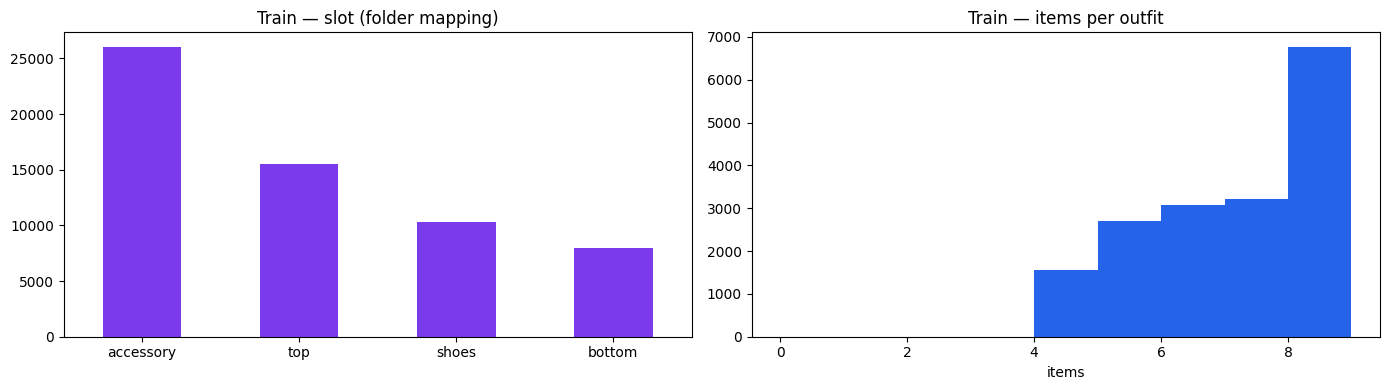

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(summary["train"]["slot_counts_folder"]).sort_values(ascending=False).plot.bar(
    ax=axes[0], color="#7C3AED", title="Train — slot (folder mapping)")
axes[0].tick_params(axis="x", rotation=0)
axes[1].hist(train_items_per, bins=range(0, max(train_items_per) + 2), color="#2563EB")
axes[1].set_title("Train — items per outfit")
axes[1].set_xlabel("items")
plt.tight_layout()
plt.show()

## 3. Temuan kunci

- **Fashion** siap dilatih: setelah cleaning tersisa ±33,6 ribu gambar, semua 24 kelas `article_type` ada.
- **Polyvore** hanya ±55% item pada `*_no_dup.json` memiliki file gambar di `Re-PolyVore/`,
  dan hanya ±24% outfit *train* punya lengkap slot inti (top+bottom+shoes) **beserta** gambarnya.
  → `03_prepare_polyvore.py` (tahap berikutnya) **wajib** memfilter ke outfit yang gambarnya tersedia.
- Jumlah gambar yang hilang membuat dataset tetap bisa dipakai, tetapi ukuran data latih scorer lebih kecil.

In [11]:
fashion_report = {
    "rows_raw": int(len(styles)),
    "images_present": int(exists.sum()),
    "images_missing": int((~exists).sum()),
    "clean_rows": int(len(clean)),
    "clean_stats": {k: int(v) for k, v in clean_stats.items()},
    "split_sizes": {str(k): int(v) for k, v in split_preview["split"].value_counts().items()},
    "article_counts": {str(k): int(v) for k, v in clean["article_type"].value_counts().items()},
    "colour_counts": {str(k): int(v) for k, v in clean["base_colour"].value_counts().items()},
}
(ARTIFACT_DIR / "fashion_eda_summary.json").write_text(
    json.dumps(fashion_report, indent=2, ensure_ascii=False), encoding="utf-8")
poly_report = {k: {kk: vv for kk, vv in v.items()} for k, v in summary.items()}
(ARTIFACT_DIR / "polyvore_eda_summary.json").write_text(
    json.dumps(poly_report, indent=2, ensure_ascii=False), encoding="utf-8")
print("Ringkasan disimpan di:", cu.to_posix(ARTIFACT_DIR))

Ringkasan disimpan di: C:/Kuliah/Semester 5/neurfit/ml/artifacts/eda
